In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [2]:
data = load_breast_cancer()

X = data.data
y = data.target

print("Features:", X.shape)
print("Target:", y.shape)

print("Classes:", data.target_names)

Features: (569, 30)
Target: (569,)
Classes: ['malignant' 'benign']


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [4]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [5]:
model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),

    layers.Dense(64, activation="relu"),

    layers.Dense(32, activation="relu"),

    layers.Dense(1, activation="sigmoid")
])

In [6]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [7]:
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.6236 - loss: 0.6442 - val_accuracy: 0.8791 - val_loss: 0.5109
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9396 - loss: 0.4163 - val_accuracy: 0.9341 - val_loss: 0.3475
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9533 - loss: 0.2706 - val_accuracy: 0.9670 - val_loss: 0.2330
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9588 - loss: 0.1854 - val_accuracy: 0.9670 - val_loss: 0.1654
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9643 - loss: 0.1413 - val_accuracy: 0.9780 - val_loss: 0.1272
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9698 - loss: 0.1170 - val_accuracy: 0.9780 - val_loss: 0.1037
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9725 - loss: 0.1014 - val_accuracy: 0.9780 - val_loss: 0.0878
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9725 - loss: 0.0905 - val_accuracy: 0.978

In [8]:
y_probability = model.predict(X_test)

y_prediction = (y_probability >= 0.5).astype(int)

print("Predicted:", y_prediction[:10].flatten())

print("Actual:", y_test[:10])

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
Predicted: [0 1 0 0 0 1 1 0 0 0]
Actual: [0 1 0 1 0 1 1 0 0 0]


In [9]:
accuracy = accuracy_score(
    y_test,
    y_prediction
)

print("Accuracy:", accuracy)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_prediction,
        target_names=data.target_names
    )
)

Accuracy: 0.9649122807017544

Classification Report:
              precision    recall  f1-score   support

   malignant       0.93      0.98      0.95        42
      benign       0.99      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.97      0.96       114
weighted avg       0.97      0.96      0.97       114



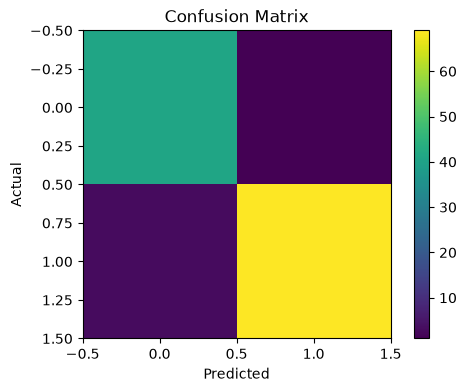

In [10]:
cm = confusion_matrix(
    y_test,
    y_prediction
)

plt.figure(figsize=(6, 4))

plt.imshow(cm)

plt.title("Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.colorbar()

plt.show()